# Datalab I — Sprint 3: Data inspecteren en opschonen

**Opleiding:** Applied Data Science & AI — De Haagse Hogeschool  
**Dataset:** CBS, tabel `85618NED`  
**Datum:** 3 november 2026  

### Teamleden

| Studentnaam | Studentnummer |
|---|---|
| *Jamal Anches Gallego* | *25108328* |
| *John Shoghnani* | *24073806* |
| *Kaan Alhan* | *24132667* |
| *Dean Groise* | *23046910* |
| *Kyra van Bennekom* | *23115033* |
| *Freya den Hollander* | *24051772* |


## Doel en onderzoeksvraag

In dit notebook onderzoeken we de CBS-dataset op buurtniveau. We controleren de structuur en datakwaliteit, verwijderen kolommen volgens een vastgelegde aanpak en berekenen beschrijvende statistieken, gemeentetotalen en demografische percentages.

**Centrale vraag:** In hoeverre is de gebruikte CBS-buurtendataset geschikt als basis voor verdere analyse, en welke beperkingen moeten daarbij worden meegenomen?

### Leeswijzer

De stappen zijn achtereenvolgens: importeren, verkennen, filteren, opschonen, basisstatistieken, vergelijking met CBS en percentages. Bestaande code is ongewijzigd gebleven. Resultaten en conclusies moeten worden gecontroleerd na uitvoering van alle cellen.

**Bron:** Centraal Bureau voor de Statistiek (CBS), StatLine-tabel `85618NED`, opgehaald met `cbsodata`. Vermeld bij inlevering ook de raadpleegdatum en officiële tabeltitel.

## 1. Benodigde bibliotheken

De onderstaande bestaande cel installeert de bibliotheek `cbsodata`. Voer de installatie alleen uit als dat in de gebruikte omgeving nodig is.

In [2]:
!python -m pip install cbsodata


## 2. Dataset importeren

Met de CBS API wordt tabel `85618NED` opgehaald en omgezet naar een pandas-dataframe (`df`). De eerste selectie op `SoortRegio_2` maakt een dataframe met buurten. De omvang van de volledige dataset wordt weergegeven met `df.shape`.

In [3]:
import cbsodata
import pandas as pd

# Gebruik een CBS-tabelcode (bijv. '83765ned' voor bevolkingsdata)
tabelcode = '85618NED'

# Haal de data direct op
data = cbsodata.get_data(tabelcode)
# Laad de data in een DataFrame
df = pd.DataFrame(data)

# Toon de eerste 5 rijen

buurten = df[df['SoortRegio_2'] == 'Buurt     ']
# door te filteren op de buurten, kunnen we de data beter analyseren en visualiseren, omdat buurten vaak specifieke kenmerken hebben die relevant zijn voor energiebedrijven om de energiebehoefte en -consumptie in kaart te brengen. Door te focussen op buurten kunnen we gerichte inzichten verkrijgen die kunnen helpen bij het optimaliseren van energievoorziening en -beleid.
df.shape


(18116, 128)

## 3. Eerste verkenning van de gegevens

We onderzoeken eerst welke regio-indelingen in de oorspronkelijke dataset voorkomen. Dit helpt om te controleren dat de latere analyses op één geografisch niveau worden uitgevoerd.

In [4]:
df['SoortRegio_2'].unique() 

<ArrowStringArray>
['Land      ', 'Gemeente  ', 'Wijk      ', 'Buurt     ']
Length: 4, dtype: str

### 3.1 Ontbrekende waarden en datatypes

De bestaande code toont per kolom het aantal ontbrekende waarden en het datatype. Controleer bij de interpretatie of ontbrekende waarden voor de analyse relevante variabelen treffen. De comments in de code zijn voorlopige observaties en moeten overeenkomen met de daadwerkelijke uitvoer.

In [5]:
print(buurten.isna().sum())
print(buurten.dtypes)

#5 rijen en 128 kolommen
#types zijn float64, int64 en str, dtype is object
#missende waarden zijn bij dekkingspercentage_124; 96, matevanstedelijkheid_125; 84 en omgevingsadressendichtheid_126; 84
#de eenheden die in deze dataset zijn gebruikt zijn: aantal, per 1000 inwoners, aantal inwoners per km2, euro's, percentages, kWh, m3, km2, km, ha, code


ID                                 0
WijkenEnBuurten                    0
Gemeentenaam_1                     0
SoortRegio_2                       0
Codering_3                         0
                                  ..
OppervlakteWater_122               0
MeestVoorkomendePostcode_123       0
Dekkingspercentage_124            96
MateVanStedelijkheid_125          84
Omgevingsadressendichtheid_126    84
Length: 128, dtype: int64
ID                                  int64
WijkenEnBuurten                       str
Gemeentenaam_1                        str
SoortRegio_2                          str
Codering_3                            str
                                   ...   
OppervlakteWater_122                int64
MeestVoorkomendePostcode_123          str
Dekkingspercentage_124            float64
MateVanStedelijkheid_125          float64
Omgevingsadressendichtheid_126    float64
Length: 128, dtype: object


### 3.2 Datasetbeschrijving en eerste statistieken

Met `describe()` bekijken we de numerieke verdelingen en met de volledige dataframeweergave de aanwezige kolommen. Voor het rubricniveau **Uitstekend** is daarnaast een controleerbaar overzicht per kolom nodig met betekenis, datatype, eenheid en ontbrekende waarden. De onderstaande code levert nog niet automatisch dat volledige overzicht.

In [6]:
display(buurten.describe())
display(buurten.iloc[:,:])
#bescrijvingen per kolom:
#Bevolking: aantal inwoners, geslachten, leeftijdsgroepen, allochtonen (autochtoon, niet-westerse, westerse).
#Wonen: aantal woningen, koop/huurverhouding, WOZ-waarde, leegstand, sociale huurwoningen, huishoudensgrootte.
#Inkomen: gemiddeld en mediaan inkomen, lage-inkomenshuishoudens, bijstandsontvangers, AOW-ontvangers.
#Energie: gas- en elektriciteitsverbruik, zonnepanelen, energiearmoedehuishoudens.
#Vervoer: aantal motorvoertuigen en personenauto’s, elektrische auto’s, openbaar vervoergebruik, parkeerplaatsen.
#Veiligheid: misdrijven (totaal en per 1.000 inwoners), woninginbraken, verkeersongevallen.
#Onderwijs: aantal basisschool- en middelbare scholieren, hoogopgeleiden (HBO/WO).
#Bedrijven: aantal bedrijven, banen (voltijdsequivalenten), startende bedrijven, faillissementen.
#Milieu: groenoppervlak, stedelijkheid, oppervlakte buurt.
#Voorzieningen: afstand tot basisschool, middelbare school en kinderdagverblijf, aantal scholen en kinderopvanglocaties in de buurt.
#Identificatie: buurtcode, buurtnaam, wijkcode, wijknaam, gemeentecode, gemeentenaam, provincie.

,ID,AantalInwoners_5,Mannen_6,Vrouwen_7,k_0Tot15Jaar_8,k_15Tot25Jaar_9,k_25Tot45Jaar_10,k_45Tot65Jaar_11,k_65JaarOfOuder_12,Ongehuwd_13,...,AfstandTotGroteSupermarkt_116,AfstandTotKinderdagverblijf_117,AfstandTotSchool_118,ScholenBinnen3Km_119,OppervlakteTotaal_120,OppervlakteLand_121,OppervlakteWater_122,Dekkingspercentage_124,MateVanStedelijkheid_125,Omgevingsadressendichtheid_126
count,14421.000000,14421.000000,14421.000000,14421.000000,14421.000000,14421.000000,14421.000000,14421.000000,14421.000000,14421.000000,...,13668.000000,13668.000000,13668.000000,13668.000000,14421.000000,14421.000000,14421.000000,14325.000000,14337.000000,14337.000000
mean,9017.870883,1235.024270,613.673809,621.348728,189.147077,151.883711,312.513695,331.758200,249.710145,613.746273,...,1.593437,1.141308,1.195910,6.742706,243.259899,233.318078,9.928715,1.255079,3.553812,1224.455814
std,5236.883157,1609.106229,793.833311,816.858689,267.708033,223.740814,465.505961,418.982896,336.571257,873.336365,...,1.374546,0.983929,0.951566,6.584308,537.572591,519.699332,52.688322,0.836123,1.479556,1510.914445
min,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.100000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000
25%,4447.000000,185.000000,95.000000,90.000000,25.000000,20.000000,35.000000,55.000000,35.000000,80.000000,...,0.600000,0.500000,0.500000,2.000000,25.000000,24.000000,0.000000,1.000000,2.000000,175.000000
50%,9011.000000,710.000000,360.000000,355.000000,95.000000,80.000000,155.000000,200.000000,135.000000,325.000000,...,1.100000,0.800000,0.800000,5.000000,55.000000,53.000000,1.000000,1.000000,4.000000,767.000000
75%,13550.000000,1695.000000,840.000000,855.000000,255.000000,195.000000,415.000000,455.000000,340.000000,815.000000,...,2.200000,1.600000,1.600000,9.500000,191.000000,178.000000,4.000000,1.000000,5.000000,1731.000000
max,18115.000000,29265.000000,14025.000000,15240.000000,5095.000000,3905.000000,8670.000000,6870.000000,7870.000000,15565.000000,...,14.000000,13.100000,13.200000,55.300000,13016.000000,12816.000000,2296.000000,6.000000,5.000000,12559.000000


,ID,WijkenEnBuurten,Gemeentenaam_1,SoortRegio_2,Codering_3,IndelingswijzigingGemeenteWijkBuurt_4,AantalInwoners_5,Mannen_6,Vrouwen_7,k_0Tot15Jaar_8,...,AfstandTotKinderdagverblijf_117,AfstandTotSchool_118,ScholenBinnen3Km_119,OppervlakteTotaal_120,OppervlakteLand_121,OppervlakteWater_122,MeestVoorkomendePostcode_123,Dekkingspercentage_124,MateVanStedelijkheid_125,Omgevingsadressendichtheid_126
3,3,Annen,Aa en Hunze,Buurt,BU16800000,1,3450,1680,1775,495,...,0.5,0.8,2.5,252,252,0,9468,1.0,5.0,410.0
4,4,Verspreide huizen Annen,Aa en Hunze,Buurt,BU16800009,1,150,75,80,15,...,1.8,2.0,1.2,1226,1213,13,9468,1.0,5.0,59.0
6,6,Eext,Aa en Hunze,Buurt,BU16800100,1,1270,655,620,185,...,1.2,0.9,1.0,171,170,1,9463,1.0,5.0,147.0
7,7,Verspreide huizen Eext,Aa en Hunze,Buurt,BU16800109,1,180,90,90,10,...,2.0,2.1,1.3,1618,1614,4,9463,1.0,5.0,37.0
9,9,Anloo,Aa en Hunze,Buurt,BU16800200,1,325,165,160,45,...,2.5,0.5,2.0,57,57,0,9467,1.0,5.0,95.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18110,18110,Gerenlanden,Zwolle,Buurt,BU01935140,1,3025,1480,1540,535,...,0.5,0.5,12.0,58,55,2,8014,1.0,2.0,1958.0
18111,18111,Gerenbroek,Zwolle,Buurt,BU01935150,1,3040,1520,1515,550,...,0.5,0.5,11.7,49,47,2,8014,1.0,2.0,1613.0
18112,18112,Oude Mars,Zwolle,Buurt,BU01935160,1,200,105,95,45,...,1.8,1.8,7.5,45,43,2,8015,1.0,4.0,759.0
18114,18114,Windesheim,Zwolle,Buurt,BU01935200,1,410,200,205,85,...,0.3,0.3,1.0,53,53,0,8015,1.0,5.0,62.0


---
## 4. Consistente granulariteit: buurten

De dataset kan verschillende geografische niveaus bevatten. Door uitsluitend buurten te selecteren voorkomen we dat gegevens van gemeenten en buurten in dezelfde vergelijking worden behandeld. Dit is belangrijk omdat gemeenten buurten omvatten en anders dubbeltellingen of misleidende vergelijkingen kunnen ontstaan.


## Data opschonen

### 1. Dataset inspecteren


We filteren op alleen buurten zodat alle rijen op hetzelfde niveau zitten en we geen buurten met hele gemeenten optellen of vergelijken.

In [7]:
# Dataframe buurten maken
buurten = df[df['SoortRegio_2'].str.strip() == 'Buurt']

In [8]:
buurten.info()

<class 'pandas.DataFrame'>
Index: 14421 entries, 3 to 18115
Columns: 128 entries, ID to Omgevingsadressendichtheid_126
dtypes: float64(79), int64(43), str(6)
memory usage: 15.4 MB


### 4.1 Keuzes bij het opschonen

De bestaande werkwijze verwijdert kolommen wanneer meer dan 30% van de waarden ontbreekt. Dat is een gekozen kwaliteitsdrempel, **geen algemeen bewezen standaard**. Voor een beoordeling op *Uitstekend* moet deze keuze nog worden onderbouwd met een passende bron of een analyse van de gevolgen van verschillende drempels.

Daarnaast worden drie administratieve kolommen verwijderd. Controleer dat de kolommen die nodig zijn voor identificatie, koppeling en toekomstige energieanalyses behouden blijven.

### Waarom buurten filteren en data opschonen?
- **Alleen buurten:** We vergelijken alleen buurten met elkaar en geen gemeenten of landsdelen, zodat alle rijen op hetzelfde niveau liggen (consistente granulariteit).
- **Drempelwaarde lege vakjes (30%):** Als meer dan 30% van de gegevens ontbreekt, vinden wij de kolom te onbetrouwbaar om mee te rekenen.
- **Relevante kolommen:** Kenmerken zoals woningtype (bijv. tussenwoning, appartement, vrijstaand) en huishoudensgrootte houden we, omdat die direct invloed hebben op stroomverbruik.
- **Niet-relevante kolommen:** Administratieve kolommen zoals 'ID', 'Codering_3' en 'SoortRegio_2' hebben geen voorspellende waarde en worden verwijderd.

### 4.2 Opschoning uitvoeren en controleren

De code maakt `buurten_schoon` en vergelijkt het aantal rijen en kolommen vóór en na de opschoning. Noteer op basis van de uitvoer hoeveel kolommen daadwerkelijk zijn verwijderd en of het aantal buurten gelijk is gebleven.

In [9]:
# 1. Kolommen met meer dan 30% ontbrekende waarden verwijderen
grens = 0.70 * len(buurten)
buurten_schoon = buurten.dropna(thresh=grens, axis=1)

# 2. Niet-relevante kolommen verwijderen
nutteloos = ['ID', 'Codering_3', 'SoortRegio_2']
buurten_schoon = buurten_schoon.drop(columns=[col for col in nutteloos if col in buurten_schoon.columns])

# 3. Eindresultaat controleren
print("Voor opschonen:", buurten.shape)
print("Na opschonen:", buurten_schoon.shape)

Voor opschonen: (14421, 128)
Na opschonen: (14421, 106)


---
## 5. Basisstatistieken

In dit onderdeel worden de basisstatistieken, gemeentetotalen en percentages berekend met de bestaande codecellen.


### 5.1 Beschrijvende basisstatistieken

#### Basisstatistieken

**Basisstatistieken berekenen**

Om de dataset verder te verkennen, berekenen we de basisstatistieken van alle numerieke kolommen uit het opgeschoonde dataframe buurten_schoon.

Per numerieke kolom berekenen we:

**Minimum:** De laagste waarde.

**Maximum:** De hoogste waarde.

**Gemiddelde:** De som van alle waarden gedeeld door het aantal beschikbare waarden.

**Mediaan:** De middelste waarde wanneer alle waarden van laag naar hoog worden gesorteerd.

Ontbrekende waarden worden automatisch buiten de berekeningen gehouden. De resultaten worden weergegeven in een Markdown-tabel, zodat de verschillende variabelen overzichtelijk vergeleken kunnen worden.

In [10]:
# Basisstatistieken:

## Dean
# Minimum: De laagste waarde.
# Maximum: De hoogste waarde.
# Gemiddelde: De som van alle waarden gedeeld door het aantal beschikbare waarden.
# Mediaan: De middelste waarde wanneer alle waarden van laag naar hoog worden gesorteerd.

# Basisstatistieken berekenen voor alle numerieke kolommen

# Controleer eerst of de opgeschoonde dataset beschikbaar is.
# Deze variabele wordt aangemaakt in de cel "Kolommen opschonen" hierboven.
if "buurten_schoon" not in globals():
    raise RuntimeError(
        "De dataset 'buurten_schoon' bestaat nog niet. Voer eerst de eerdere cellen uit, "
        "met name de cel waarin 'buurten_schoon' wordt aangemaakt. "
        "Kies eventueel Kernel > Restart Kernel and Run All Cells."
    )

# Selecteer alle numerieke kolommen uit de opgeschoonde dataset
numerieke_kolommen = buurten_schoon.select_dtypes(include="number").columns

if len(numerieke_kolommen) == 0:
    raise ValueError("Er zijn geen numerieke kolommen gevonden in 'buurten_schoon'.")

# Bereken minimum, maximum, gemiddelde en mediaan per numerieke kolom
basisstatistieken = buurten_schoon[numerieke_kolommen].agg(
    ["min", "max", "mean", "median"]
).T

# Geef de statistieken Nederlandse kolomnamen en rond af op twee decimalen
basisstatistieken = basisstatistieken.rename(columns={
    "min": "Minimum",
    "max": "Maximum",
    "mean": "Gemiddelde",
    "median": "Mediaan"
}).round(2)

# Maak zelf een Markdown-tabel. Hiervoor is de extra package 'tabulate' niet nodig.
def dataframe_naar_markdown(dataframe):
    tabel = dataframe.copy()
    tabel.insert(0, "Numerieke kolom", tabel.index.astype(str))

    def formatteer_waarde(waarde):
        if pd.isna(waarde):
            return "—"
        return str(waarde).replace("|", r"\|").replace("\n", " ")

    kop = "| " + " | ".join(formatteer_waarde(kolom) for kolom in tabel.columns) + " |"
    scheiding = "| " + " | ".join("---" for _ in tabel.columns) + " |"
    rijen = [
        "| " + " | ".join(formatteer_waarde(waarde) for waarde in rij) + " |"
        for rij in tabel.itertuples(index=False, name=None)
    ]
    return "\n".join([kop, scheiding] + rijen)

from IPython.display import display, Markdown

display(Markdown(dataframe_naar_markdown(basisstatistieken)))

| Numerieke kolom | Minimum | Maximum | Gemiddelde | Mediaan |
| --- | --- | --- | --- | --- |
| AantalInwoners_5 | 0.0 | 29265.0 | 1235.02 | 710.0 |
| Mannen_6 | 0.0 | 14025.0 | 613.67 | 360.0 |
| Vrouwen_7 | 0.0 | 15240.0 | 621.35 | 355.0 |
| k_0Tot15Jaar_8 | 0.0 | 5095.0 | 189.15 | 95.0 |
| k_15Tot25Jaar_9 | 0.0 | 3905.0 | 151.88 | 80.0 |
| k_25Tot45Jaar_10 | 0.0 | 8670.0 | 312.51 | 155.0 |
| k_45Tot65Jaar_11 | 0.0 | 6870.0 | 331.76 | 200.0 |
| k_65JaarOfOuder_12 | 0.0 | 7870.0 | 249.71 | 135.0 |
| Ongehuwd_13 | 0.0 | 15565.0 | 613.75 | 325.0 |
| Gehuwd_14 | 0.0 | 9200.0 | 465.24 | 280.0 |
| Gescheiden_15 | 0.0 | 3100.0 | 96.19 | 45.0 |
| Verweduwd_16 | 0.0 | 2075.0 | 59.89 | 25.0 |
| Nederland_17 | 0.0 | 16390.0 | 899.94 | 550.0 |
| EuropaExclusiefNederland_18 | 0.0 | 4365.0 | 112.11 | 45.0 |
| BuitenEuropa_19 | 0.0 | 12980.0 | 222.97 | 45.0 |
| Nederland_20 | 0.0 | 16390.0 | 899.91 | 550.0 |
| EuropaExclusiefNederland_21 | 0.0 | 1060.0 | 41.95 | 20.0 |
| BuitenEuropa_22 | 0.0 | 6310.0 | 100.63 | 20.0 |
| EuropaExclusiefNederland_23 | 0.0 | 3790.0 | 70.17 | 20.0 |
| BuitenEuropa_24 | 0.0 | 6670.0 | 122.33 | 25.0 |
| GeboorteTotaal_25 | 0.0 | 320.0 | 11.38 | 5.0 |
| GeboorteRelatief_26 | 0.0 | 235.0 | 7.96 | 8.0 |
| SterfteTotaal_27 | 0.0 | 455.0 | 11.77 | 5.0 |
| SterfteRelatief_28 | 0.0 | 551.0 | 8.95 | 6.0 |
| HuishoudensTotaal_29 | 0.0 | 14180.0 | 573.39 | 310.0 |
| Eenpersoonshuishoudens_30 | 0.0 | 7485.0 | 226.42 | 90.0 |
| HuishoudensZonderKinderen_31 | 0.0 | 3265.0 | 163.59 | 95.0 |
| HuishoudensMetKinderen_32 | 0.0 | 4650.0 | 183.43 | 100.0 |
| GemiddeldeHuishoudensgrootte_33 | 1.0 | 6.0 | 2.27 | 2.3 |
| Bevolkingsdichtheid_34 | 0.0 | 55375.0 | 3239.39 | 2001.0 |
| Woningvoorraad_35 | 0.0 | 14277.0 | 563.43 | 305.0 |
| GemiddeldeWOZWaardeVanWoningen_36 | 34.0 | 2236.0 | 415.88 | 388.0 |
| PercentageEengezinswoning_37 | 0.0 | 100.0 | 76.21 | 87.0 |
| PercentageMeergezinswoning_38 | 0.0 | 100.0 | 23.79 | 13.0 |
| PercentageBewoond_39 | 0.0 | 100.0 | 94.53 | 96.0 |
| PercentageOnbewoond_40 | 0.0 | 100.0 | 5.47 | 4.0 |
| Koopwoningen_41 | 0.0 | 100.0 | 68.09 | 74.0 |
| HuurwoningenTotaal_42 | 0.0 | 100.0 | 31.77 | 26.0 |
| InBezitWoningcorporatie_43 | 0.0 | 100.0 | 18.33 | 13.0 |
| InBezitOverigeVerhuurders_44 | 0.0 | 100.0 | 13.44 | 9.0 |
| EigendomOnbekend_45 | 0.0 | 33.0 | 0.13 | 0.0 |
| BouwjaarVoor2000_46 | 0.0 | 100.0 | 80.35 | 88.0 |
| BouwjaarVanaf2000_47 | 0.0 | 100.0 | 19.65 | 12.0 |
| GemiddeldeElektriciteitsleveringTotaal_48 | 890.0 | 8310.0 | 3002.02 | 2830.0 |
| VrijstaandeWoning_53 | 1560.0 | 8310.0 | 3932.02 | 3900.0 |
| Huurwoning_54 | 790.0 | 6380.0 | 2347.54 | 2080.0 |
| EigenWoning_55 | 1380.0 | 8310.0 | 3239.11 | 3090.0 |
| GemiddeldAardgasverbruikTotaal_56 | 0.0 | 3540.0 | 1007.5 | 990.0 |
| VrijstaandeWoning_61 | 0.0 | 4010.0 | 1363.63 | 1350.0 |
| Huurwoning_62 | 0.0 | 2760.0 | 875.38 | 800.0 |
| EigenWoning_63 | 0.0 | 3530.0 | 1061.61 | 1060.0 |
| LeerlingenPo_65 | 0.0 | 2810.0 | 101.58 | 50.0 |
| LeerlingenVoInclVavo_66 | 0.0 | 1490.0 | 66.08 | 40.0 |
| StudentenMboExclExtranei_67 | 0.0 | 1100.0 | 32.62 | 20.0 |
| StudentenHbo_68 | 0.0 | 1240.0 | 31.29 | 10.0 |
| StudentenWo_69 | 0.0 | 2280.0 | 22.32 | 0.0 |
| WerkzameBeroepsbevolking_73 | 0.0 | 13290.0 | 662.03 | 380.0 |
| Nettoarbeidsparticipatie_74 | 14.0 | 95.0 | 72.71 | 73.0 |
| AantalInkomensontvangers_79 | 0.0 | 22500.0 | 996.45 | 600.0 |
| GemiddeldInkomenPerInkomensontvanger_80 | 7.8 | 151.3 | 40.55 | 39.0 |
| GemiddeldInkomenPerInwoner_81 | 7.4 | 108.0 | 33.73 | 32.7 |
| k_40PersonenMetLaagsteInkomen_82 | 8.0 | 93.3 | 39.42 | 39.0 |
| k_20PersonenMetHoogsteInkomen_83 | 0.0 | 65.7 | 20.69 | 19.8 |
| k_40HuishoudensMetLaagsteInkomen_85 | 0.9 | 100.0 | 35.64 | 33.1 |
| k_20HuishoudensMetHoogsteInkomen_86 | 0.0 | 79.8 | 23.14 | 21.3 |
| HuishoudensMetEenLaagInkomen_87 | 0.0 | 45.1 | 3.3 | 2.6 |
| HuishOnderOfRondSociaalMinimum_88 | 0.0 | 38.2 | 5.27 | 4.1 |
| HuishoudensTot110VanSociaalMinimum_89 | 0.0 | 58.7 | 7.94 | 6.2 |
| HuishoudensTot120VanSociaalMinimum_90 | 0.0 | 70.9 | 10.14 | 8.2 |
| MediaanVermogenVanParticuliereHuish_91 | -6.1 | 3016.0 | 234.09 | 207.6 |
| PersonenPerSoortUitkeringBijstand_92 | 0.0 | 1790.0 | 31.12 | 10.0 |
| PersonenPerSoortUitkeringAO_93 | 0.0 | 1470.0 | 59.87 | 30.0 |
| PersonenPerSoortUitkeringWW_94 | 0.0 | 280.0 | 11.03 | 10.0 |
| PersonenPerSoortUitkeringAOW_95 | 0.0 | 7220.0 | 253.03 | 150.0 |
| WmoClienten_98 | 10.0 | 3580.0 | 117.45 | 70.0 |
| WmoClientenRelatief_99 | 4.0 | 896.0 | 69.23 | 58.0 |
| BedrijfsvestigingenTotaal_100 | 0.0 | 5585.0 | 163.54 | 100.0 |
| ALandbouwBosbouwEnVisserij_101 | 0.0 | 385.0 | 5.88 | 0.0 |
| BFNijverheidEnEnergie_102 | 0.0 | 1285.0 | 26.73 | 15.0 |
| GIHandelEnHoreca_103 | 0.0 | 1055.0 | 31.24 | 15.0 |
| HJVervoerInformatieEnCommunicatie_104 | 0.0 | 610.0 | 14.23 | 5.0 |
| KLFinancieleDienstenOnroerendGoed_105 | 0.0 | 500.0 | 14.04 | 10.0 |
| MNZakelijkeDienstverlening_106 | 0.0 | 1965.0 | 43.19 | 25.0 |
| OQOverheidOnderwijsEnZorg_107 | 0.0 | 650.0 | 31.05 | 20.0 |
| RUCultuurRecreatieOverigeDiensten_108 | 0.0 | 535.0 | 20.38 | 10.0 |
| PersonenautoSTotaal_109 | 0.0 | 62120.0 | 593.91 | 370.0 |
| PersonenautoSBrandstofBenzine_110 | 0.0 | 33740.0 | 472.35 | 290.0 |
| PersonenautoSOverigeBrandstof_111 | 0.0 | 32750.0 | 121.55 | 75.0 |
| PersonenautoSPerHuishouden_112 | 0.0 | 2.5 | 1.17 | 1.2 |
| PersonenautoSNaarOppervlakte_113 | 0.0 | 14129.0 | 1603.56 | 1468.0 |
| Motorfietsen_114 | 0.0 | 605.0 | 47.75 | 30.0 |
| AfstandTotHuisartsenpraktijk_115 | 0.0 | 13.5 | 1.72 | 1.2 |
| AfstandTotGroteSupermarkt_116 | 0.0 | 14.0 | 1.59 | 1.1 |
| AfstandTotKinderdagverblijf_117 | 0.0 | 13.1 | 1.14 | 0.8 |
| AfstandTotSchool_118 | 0.1 | 13.2 | 1.2 | 0.8 |
| ScholenBinnen3Km_119 | 0.0 | 55.3 | 6.74 | 5.0 |
| OppervlakteTotaal_120 | 0.0 | 13016.0 | 243.26 | 55.0 |
| OppervlakteLand_121 | 0.0 | 12816.0 | 233.32 | 53.0 |
| OppervlakteWater_122 | 0.0 | 2296.0 | 9.93 | 1.0 |
| Dekkingspercentage_124 | 1.0 | 6.0 | 1.26 | 1.0 |
| MateVanStedelijkheid_125 | 1.0 | 5.0 | 3.55 | 4.0 |
| Omgevingsadressendichtheid_126 | 1.0 | 12559.0 | 1224.46 | 767.0 |


---
## 6. Vergelijking met officiële CBS-gemeentecijfers

De bestaande code telt inwonersaantallen per gemeente op uit de buurtgegevens en vergelijkt deze met gemeentecijfers uit de oorspronkelijke CBS-dataset. Het verschil wordt berekend als **eigen totaal minus CBS-totaal**.

**Interpretatie na uitvoering:** bespreek voor de getoonde gemeenten de grootte en richting van de verschillen. Afronding van buurtaantallen kan een verklaring zijn, maar mag niet zonder controle als enige oorzaak worden aangenomen.

###
Voor een selectie van gemeenten vergelijken we de opgesomde buurttotalen met de officiële gemeentecijfers van het CBS. Kleine verschillen ontstaan doordat het CBS buurtaantallen om privacyredenen afrondt op vijftallen; doordat deze afrondingen per afzonderlijke buurt worden opgeteld, cumuleert het afrondingsverschil vooral bij grotere gemeenten met veel buurten.

In [11]:
# Basisstatistieken:

##kyra
# Totalen per gemeente 
# geschikte kolommen voor totalen selecteren
# totalen per gemeente berekenen .groupby()
# aantal inwoners per gemeeente  

import pandas as pd
#meetwaarden data set obs=observations
df_obs= pd.read_csv("Observations.csv", sep=";" )
#gebiedscodes & namen 
df_regios= pd.read_csv("WijkenEnBuurtenCodes.csv", sep=";")
#rijen & kolom namen 
print("Observattions:")
display(df_obs.head(3))

print("regio codes:")
display(df_regios.head(3))

#gegevens koppelen per gemeente 
df_totaal= pd.merge(df_obs, df_regios, how="left", left_on= "WijkenEnBuurten", right_on="Identifier")
display(df_totaal.head(5))

# filteren enkel data gemeente GM  (geschikte kolommen voor totalen selecteren)
df_totaal ["Value"]= pd.to_numeric(df_totaal["Value"], errors="coerce")
# aantal inwoners per gemeeente  
df_gemeente_inwoners= df_totaal[(df_totaal["DimensionGroupId"]== "GM") & (df_totaal["Measure"]=="T001036" )]
#groepeer per gemeente  (totalen per gemeente berekenen .groupby())
totalen_per_gemeente= (df_gemeente_inwoners.groupby("Title")["Value"].sum().reset_index())
display(totalen_per_gemeente.head())

Observattions:


,Id,Measure,WijkenEnBuurten,Value,StringValue,ValueAttribute
0,0,GM000C,NL00,NaN,Nederland,NaN
1,1,R00003,NL00,NaN,Land,NaN
2,2,R00004,NL00,NaN,NL00,NaN


regio codes:


,Identifier,DimensionGroupId,DimensionId,Index,Title,Description,DetailRegionCode
0,NL00,NL,WijkenEnBuurten,1,Nederland,NaN,NaN
1,GM1680,GM,WijkenEnBuurten,2,Aa en Hunze,Gemeente 'Aa en Hunze' (GM1680),GM1680
2,WK168000,GM1680,WijkenEnBuurten,3,Wijk 00 Annen,Wijk 'Wijk 00 Annen' (WK168000) is een wijk in...,WK168000


,Id,Measure,WijkenEnBuurten,Value,StringValue,ValueAttribute,Identifier,DimensionGroupId,DimensionId,Index,Title,Description,DetailRegionCode
0,0,GM000C,NL00,NaN,Nederland,NaN,NL00,NL,WijkenEnBuurten,1,Nederland,NaN,NaN
1,1,R00003,NL00,NaN,Land,NaN,NL00,NL,WijkenEnBuurten,1,Nederland,NaN,NaN
2,2,R00004,NL00,NaN,NL00,NaN,NL00,NL,WijkenEnBuurten,1,Nederland,NaN,NaN
3,3,T001036,NL00,17811291,NaN,NaN,NL00,NL,WijkenEnBuurten,1,Nederland,NaN,NaN
4,4,3000,NL00,8850309,NaN,NaN,NL00,NL,WijkenEnBuurten,1,Nederland,NaN,NaN


,Title,Value
0,'s-Gravenhage,562839.0
1,'s-Hertogenbosch,158753.0
2,Aa en Hunze,25724.0
3,Aalsmeer,33063.0
4,Aalten,27244.0



---
## 7. Demografische percentages op buurtniveau

De bestaande code berekent percentages voor tien demografische variabelen. De formule is `aantal in groep / totaal aantal inwoners × 100`. De laatste controle telt de percentages mannen en vrouwen bij elkaar op.

**Interpretatie na uitvoering:** controleer of de percentages plausibel zijn, of buurten met nul inwoners tot ontbrekende of oneindige waarden leiden en of afronding afwijkingen van 100% kan verklaren.

In [12]:

# 1. Eigen buurttotalen berekenen
buurten_schoon["AantalInwoners_5"] = pd.to_numeric(
    buurten_schoon["AantalInwoners_5"],
    errors="coerce"
)

eigen_totalen = (
    buurten_schoon
    .groupby("Gemeentenaam_1")["AantalInwoners_5"]
    .sum()
    .reset_index()
)

eigen_totalen.columns = ["Gemeente", "Eigen_Totaal"]
eigen_totalen["Gemeente"] = eigen_totalen["Gemeente"].astype(str).str.strip()


# 2. Officiele CBS-gemeentecijfers ophalen uit originele dataset
cbs_gemeenten = df[
    df["SoortRegio_2"].astype(str).str.strip() == "Gemeente"
].copy()

# Zorg ervoor dat inwonersaantallen numeriek zijn
cbs_gemeenten["AantalInwoners_5"] = pd.to_numeric(
    cbs_gemeenten["AantalInwoners_5"],
    errors="coerce"
)

# Alleen gemeentenaam en inwonersaantal behouden
cbs_totalen = cbs_gemeenten[
    ["Gemeentenaam_1", "AantalInwoners_5"]
].copy()

cbs_totalen.columns = ["Gemeente", "CBS_Totaal"]

cbs_totalen["Gemeente"] = (
    cbs_totalen["Gemeente"].astype(str).str.strip()
)


# 3. Eigen resultaten vergelijken met CBS
vergelijking = pd.merge(
    eigen_totalen,
    cbs_totalen,
    on="Gemeente",
    how="inner"
)

vergelijking["Verschil"] = (
    vergelijking["Eigen_Totaal"] - vergelijking["CBS_Totaal"]
)


# 4. Een selectie van gemeenten tonen
selectie = [
    "'s-Gravenhage",
    "Aa en Hunze",
    "Aalsmeer",
    "Almere"
]

vergelijking_selectie = vergelijking[
    vergelijking["Gemeente"].isin(selectie)
]

display(vergelijking_selectie)


,Gemeente,Eigen_Totaal,CBS_Totaal,Verschil
0,'s-Gravenhage,562490,562839,-349
2,Aa en Hunze,25700,25724,-24
3,Aalsmeer,33065,33063,2
10,Almere,222850,222825,25


## 8. Percentages per buurt berekenen

In deze stap berekenen we percentages van verschillende demografische groepen per buurt.

Hiervoor gebruiken we:
- het aantal inwoners als noemer
- de demografische aantallen als teller

Formule:

percentage = (aantal / totaal aantal inwoners) * 100

De percentages worden toegevoegd als nieuwe kolommen aan het dataframe.

In [13]:
# Selecteer demografische kolommen
demografische_kolommen = [
    'Mannen_6',
    'Vrouwen_7',
    'k_0Tot15Jaar_8',
    'k_15Tot25Jaar_9',
    'k_25Tot45Jaar_10',
    'k_45Tot65Jaar_11',
    'k_65JaarOfOuder_12',
    'Ongehuwd_13',
    'Gehuwd_14',
    'Gescheiden_15'
]

# Zorg dat de kolommen numeriek zijn
buurten_schoon['AantalInwoners_5'] = pd.to_numeric(
    buurten_schoon['AantalInwoners_5'],
    errors='coerce'
)

for col in demografische_kolommen:

    buurten_schoon[col] = pd.to_numeric(
        buurten_schoon[col],
        errors='coerce'
    )

    # Nieuwe percentagekolom maken
    perc_colnaam = f"Perc_{col}"

    buurten_schoon[perc_colnaam] = (
        buurten_schoon[col] /
        buurten_schoon['AantalInwoners_5']
    ) * 100

# Nieuwe percentagekolommen tonen
percentagekolommen = [
    f"Perc_{col}" for col in demografische_kolommen
]

display(
    buurten_schoon[
        ['Gemeentenaam_1', 'WijkenEnBuurten', 'AantalInwoners_5']
        + percentagekolommen
    ].head()
)

# Controleren of percentages logisch zijn
buurten_schoon['Totaal_Percentage'] = (
    buurten_schoon['Perc_Mannen_6'] +
    buurten_schoon['Perc_Vrouwen_7']
)

# Controle tonen
display(
    buurten_schoon[
        ['WijkenEnBuurten', 'Totaal_Percentage']
    ].head()
)

,Gemeentenaam_1,WijkenEnBuurten,AantalInwoners_5,Perc_Mannen_6,Perc_Vrouwen_7,Perc_k_0Tot15Jaar_8,Perc_k_15Tot25Jaar_9,Perc_k_25Tot45Jaar_10,Perc_k_45Tot65Jaar_11,Perc_k_65JaarOfOuder_12,Perc_Ongehuwd_13,Perc_Gehuwd_14,Perc_Gescheiden_15
3,Aa en Hunze,Annen,3450,48.695652,51.449275,14.347826,10.289855,17.826087,30.579710,27.101449,40.434783,45.942029,7.391304
4,Aa en Hunze,Verspreide huizen Annen,150,50.000000,53.333333,10.000000,10.000000,10.000000,43.333333,30.000000,33.333333,56.666667,3.333333
6,Aa en Hunze,Eext,1270,51.574803,48.818898,14.566929,11.023622,22.047244,30.708661,21.653543,44.488189,43.307087,7.480315
7,Aa en Hunze,Verspreide huizen Eext,180,50.000000,50.000000,5.555556,8.333333,19.444444,30.555556,36.111111,41.666667,47.222222,8.333333
9,Aa en Hunze,Anloo,325,50.769231,49.230769,13.846154,9.230769,16.923077,35.384615,26.153846,38.461538,49.230769,9.230769


,WijkenEnBuurten,Totaal_Percentage
3,Annen,100.144928
4,Verspreide huizen Annen,103.333333
6,Eext,100.393701
7,Verspreide huizen Eext,100.000000
9,Anloo,100.000000



## 9. Bronnen en verantwoording

- Centraal Bureau voor de Statistiek (CBS), StatLine-tabel `85618NED`.
- Documentatie van `cbsodata`.


## Sprint 4

### Waarom correlaties berekenen en wat betekenen de cijfers?

* **Doel:** We willen zien welke kenmerken van een wijk echt invloed hebben op het stroomverbruik (`GemiddeldeElektriciteitsleveringTotaal_48`), zodat we weten met welke variabelen we straks het beste kunnen voorspellen.
* **Vuistregels (Cohen, 1988):** We kijken naar de Pearson-correlatie tussen -1 en +1; volgens de theorie van Cohen spreken we vanaf 0.5 (of onder de -0.5) van een sterk verband.
* **Wat de richting zegt:** Een positieve score betekent dat het verbruik meestijgt (bijvoorbeeld bij koopwoningen en hoog vermogen), terwijl een negatieve score juist betekent dat het verbruik daalt (zoals bij huurwoningen en corporatiebezit).

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

,GemiddeldeElektriciteitsleveringTotaal_48
EigenWoning_55,0.953541
Huurwoning_54,0.828967
PersonenautoSPerHuishouden_112,0.736332
MediaanVermogenVanParticuliereHuish_91,0.725682
k_20HuishoudensMetHoogsteInkomen_86,0.720708
Koopwoningen_41,0.695056
HuurwoningenTotaal_42,-0.694090
GemiddeldAardgasverbruikTotaal_56,0.682800
InBezitWoningcorporatie_43,-0.664778
MateVanStedelijkheid_125,0.659807


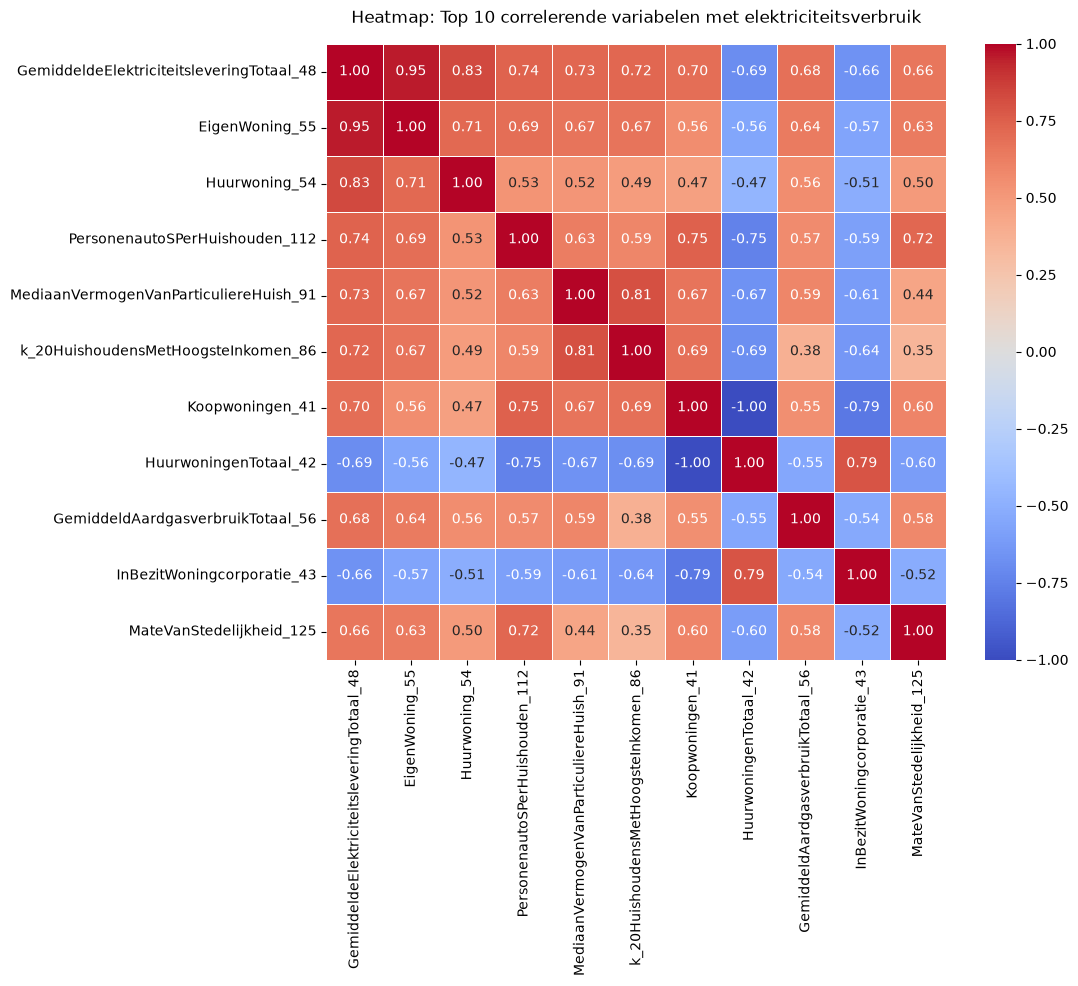

In [17]:
# 1. Bepaal doelvariabele en bereken correlatiematrix
doel = 'GemiddeldeElektriciteitsleveringTotaal_48'
corr_matrix = buurten_schoon.corr(numeric_only=True)

# 2. Correlaties sorteren op absolute sterkte (+ en -)
correlaties = corr_matrix[[doel]].drop(index=doel)
correlaties['abs'] = correlaties[doel].abs()
top_10_labels = correlaties.sort_values(by='abs', ascending=False).head(10).index.tolist()

# Tabel tonen
display(correlaties.loc[top_10_labels, [doel]])

# 3. Vierkante Heatmap maken
matrix_vars = [doel] + top_10_labels
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix.loc[matrix_vars, matrix_vars],
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5
)
plt.title("Heatmap: Top 10 correlerende variabelen met elektriciteitsverbruik", pad=15)
plt.show()